# Quality inspection of the ITS fungal community

**Question.** Is the ITS dataset in good enough shape for the downstream analyses (alpha diversity, beta diversity, differential abundance)? How sparse is the count table at ASV level and after collapsing to genus, and was every sample sequenced deeply enough to capture its richness?

**Design.** 18 independent samples (each from a different soil): 3 plant genera × 2 times × 3 replicates.

| Factor | Levels | Taken from the sample name |
|---|---|---|
| `plant_genus` | E, T, R | 1st letter |
| `Time` | B, F | 2nd letter |
| replicate | 1, 2, 3 | 3rd character |

*Example: sample `EF1` = genus **E**, time **F**, replicate **1**.*

**Checks**

| Check | Question | Level |
|---|---|---|
| Taxa per sample and sparsity | How many taxa does each sample contain, and how much of the taxa pool of its plant genus is missing from it? | ASV and genus |
| Rarefaction curves | Does the number of observed ASVs level off before the end of each sample's sequencing depth? | ASV |

**Workflow**

1. Load libraries
2. Load ASV counts and taxonomy into a `phyloseq` object and collapse a copy to genus
3. Taxa per sample and sparsity
4. Rarefaction curves (slow)
5. Reading the results

---
## 1. Setup

The packages used throughout this notebook are loaded below. phyloseq is installed from Bioconductor, and vegan, openxlsx, dplyr and ggplot2 are available from CRAN.
Bioconductor:

BiocManager::install("phyloseq")

CRAN:

install.packages(c("vegan", "openxlsx", "dplyr", "ggplot2"))

In [1]:
library(phyloseq)
library(vegan)
library(openxlsx)
library(dplyr)
library(ggplot2)

Loading required package: permute


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




---
## 2. Load the data

The Excel file has two sheets of interest: the **ASV count table** (rows = ASVs, columns = samples) and the **taxonomy** of each ASV. Sample metadata (genus and time) is read from the sample names here.

- `ps` is the **ASV-level** object.
- `ps_genus` is a copy collapsed to genus with `tax_glom()`, which sums all ASVs that belong to the same genus. `NArm = FALSE` **keeps ASVs with no genus assignment** instead of dropping them, so every taxon in `ps_genus` is either a genus or a higher rank that did not resolve to genus (as in the other notebooks). This is done because with ITS sequences alone we don't have confidance in species level assignments and keeping higher taxons avoids leakage.

> The `stopifnot()` line stops the notebook if any ASV is missing from the taxonomy table.

In [ ]:
asv <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "ITS-table", rowNames = TRUE)
asv[] <- lapply(asv, as.numeric)

tax <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "taxonomy", rowNames = TRUE)
colnames(tax) <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species", "Strain")
stopifnot(all(rownames(asv) %in% rownames(tax)))

ps <- phyloseq(otu_table(asv, taxa_are_rows = TRUE), tax_table(as.matrix(tax)))

sample_data(ps) <- data.frame(
  plant_genus = factor(substr(sample_names(ps), 1, 1), levels = c("E", "T", "R")),
  Time        = factor(substr(sample_names(ps), 2, 2), levels = c("B", "F")),
  row.names   = sample_names(ps))

ps_genus <- tax_glom(ps, taxrank = "Genus", NArm = FALSE)

ps
ps_genus

print("Both phyloseq objects should have the same sum: ")
sum(otu_table(ps))
sum(otu_table(ps_genus))

otu_ps <- as(otu_table(ps), "matrix")
otu_genus <- as(otu_table(ps_genus), "matrix")
g <- interaction(sample_data(ps)$plant_genus, sample_data(ps)$Time)

data.frame(
  Total_reads = sapply(levels(g), \(x) sum(otu_ps[, g == x])),
  Taxa = sapply(levels(g), \(x) sum(rowSums(otu_ps[, g == x, drop = FALSE]) > 0)))

data.frame(
  Total_reads = sapply(levels(g), \(x) sum(otu_genus[, g == x])),
  Taxa = sapply(levels(g), \(x) sum(rowSums(otu_genus[, g == x, drop = FALSE]) > 0)))

data.frame(
  Total_reads = colSums(otu_ps),
  Taxa = colSums(otu_ps > 0))

data.frame(
  Total_reads = colSums(otu_genus),
  Taxa = colSums(otu_genus > 0))

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7275 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 7275 taxa by 8 taxonomic ranks ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 163 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 163 taxa by 8 taxonomic ranks ]

[1] 3709021

[1] 3709021

,Total_reads,Taxa
,<dbl>,<int>
E.B,916139,2177
T.B,711476,1732
R.B,368078,2202
E.F,439728,766
T.F,460343,1031
R.F,813257,1337


,Total_reads,Taxa
,<dbl>,<int>
E.B,916139,113
T.B,711476,97
R.B,368078,108
E.F,439728,73
T.F,460343,72
R.F,813257,89


,Total_reads,Taxa
,<dbl>,<dbl>
EF1,107038,345
EB1,302045,1229
EF2,198825,335
EB2,318914,1143
EF3,133865,244
EB3,295180,1177
TF1,131902,226
TB1,208223,840
TF2,148289,263


,Total_reads,Taxa
,<dbl>,<dbl>
EF1,107038,56
EB1,302045,96
EF2,198825,44
EB2,318914,94
EF3,133865,52
EB3,295180,95
TF1,131902,39
TB1,208223,76
TF2,148289,41


---
## 3. Taxa per sample and sparsity

Two numbers are calculated at ASV level (`ps`) and at genus level (`ps_genus`):

| Measure | Formula | Variables |
|---|---|---|
| `taxa>0` | `n` | `n` = number of taxa (rows) with at least one read in the sample |
| `sparsity` | `(N − n) / N` | `N` = number of taxa with at least one read in **any** of the 6 samples (3 baseline + 3 final) of the same plant genus; `n` = `taxa>0` of the sample |

- Sparsity is measured **inside each plant genus**, not against the whole table.
- `taxa_by_sample()` prints one line per sample. The first block below is the ASV table and the second is the genus-collapsed table.

In [3]:
taxa_by_sample <- function(ps) {
  otu <- as(otu_table(ps), "matrix")
  if (!taxa_are_rows(ps)) otu <- t(otu)
  meta <- as(sample_data(ps), "data.frame")
  pool_size <- tapply(colnames(otu), interaction(meta$plant_genus, meta$Time),
    function(s) sum(rowSums(otu[, s, drop = FALSE]) > 0))
  for (s in colnames(otu)) {
    present <- sum(otu[, s] > 0)
    group <- interaction(meta[s, "plant_genus"], meta[s, "Time"])
    pool <- pool_size[as.character(group)]
    cat(s, "taxa>0:", present, "sparsity:", round((pool - present) / pool, 3), "\n")}}

cat("ASV level\n")
taxa_by_sample(ps)

cat("\nGenus level\n")
taxa_by_sample(ps_genus)

ASV level
EF1 taxa>0: 345 sparsity: 0.55 
EB1 taxa>0: 1229 sparsity: 0.435 
EF2 taxa>0: 335 sparsity: 0.563 
EB2 taxa>0: 1143 sparsity: 0.475 
EF3 taxa>0: 244 sparsity: 0.681 
EB3 taxa>0: 1177 sparsity: 0.459 
TF1 taxa>0: 226 sparsity: 0.781 
TB1 taxa>0: 840 sparsity: 0.515 
TF2 taxa>0: 263 sparsity: 0.745 
TB2 taxa>0: 942 sparsity: 0.456 
TF3 taxa>0: 692 sparsity: 0.329 
TB3 taxa>0: 960 sparsity: 0.446 
RF1 taxa>0: 563 sparsity: 0.579 
RB1 taxa>0: 1021 sparsity: 0.536 
RF2 taxa>0: 648 sparsity: 0.515 
RB2 taxa>0: 1086 sparsity: 0.507 
RF3 taxa>0: 581 sparsity: 0.565 
RB3 taxa>0: 1259 sparsity: 0.428 

Genus level
EF1 taxa>0: 56 sparsity: 0.233 
EB1 taxa>0: 96 sparsity: 0.15 
EF2 taxa>0: 44 sparsity: 0.397 
EB2 taxa>0: 94 sparsity: 0.168 
EF3 taxa>0: 52 sparsity: 0.288 
EB3 taxa>0: 95 sparsity: 0.159 
TF1 taxa>0: 39 sparsity: 0.458 
TB1 taxa>0: 76 sparsity: 0.216 
TF2 taxa>0: 41 sparsity: 0.431 
TB2 taxa>0: 83 sparsity: 0.144 
TF3 taxa>0: 62 sparsity: 0.139 
TB3 taxa>0: 79 sparsity: 0.

---
## 4. Rarefaction curves

> **Warning: the cell below takes a long time to run.** `rarecurve()` rarefies each of the 18 samples repeatedly, by default in steps of 1 read from 1 read up to the full depth of the sample, on the full ASV table, so generating the figure can take a long time (far longer than any other cell in this notebook). Run it once and avoid re-running the whole notebook unless needed. To make it faster at the price of coarser curves, pass a larger `step` to `rarecurve()` (for example `step = 100`).

A rarefaction curve shows how many ASVs are observed when only a given number of reads is drawn from a sample (Sanders 1968; Hurlbert 1971).


- Each curve ends at the real number of reads of its sample, so the x-axis also shows whether the samples were sequenced to a similar depth.
- The curves are drawn on the **ASV-level** object `ps`, not on the genus-collapsed one.
- A curve that levels off before its end point means that the extra reads mostly re-sampled ASVs already seen. A curve that is still rising means that deeper sequencing would have revealed more ASVs.

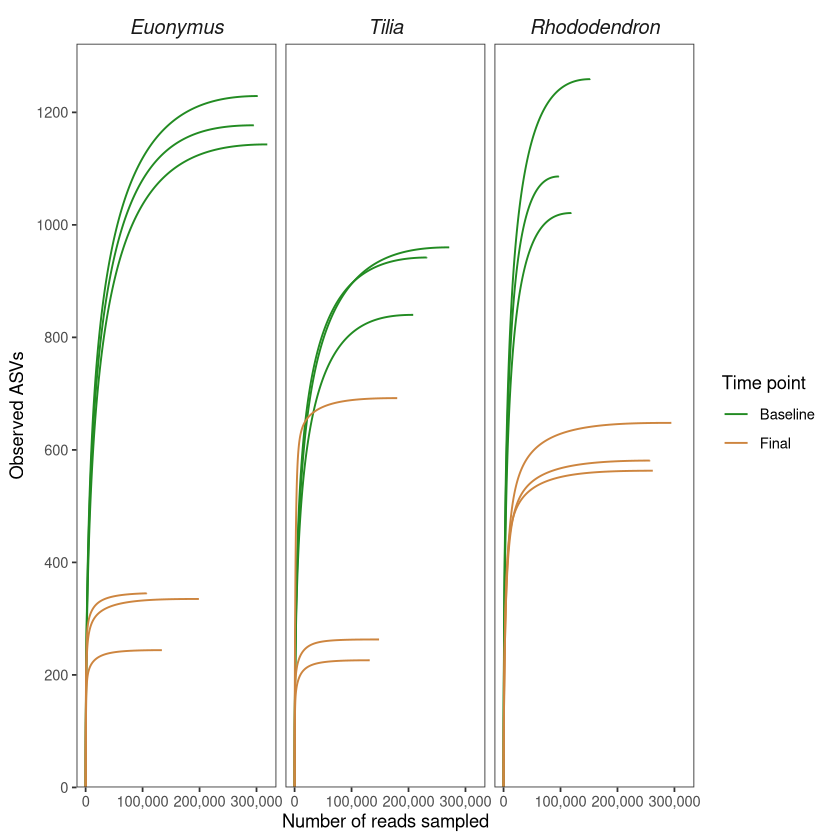

In [4]:
# WARNING: slow cell, can take a long time to run (see the note above)
otu <- as(otu_table(ps), "matrix")
if (taxa_are_rows(ps)) otu <- t(otu)
meta <- data.frame(sample_data(ps), Site = sample_names(ps))

rare_curves <- vegan::rarecurve(otu, tidy = TRUE) %>%
  dplyr::rename(ASVs = Species) %>%
  dplyr::left_join(meta, by = "Site")

ggplot(rare_curves, aes(Sample, ASVs)) +
  geom_line(aes(group = Site, color = Time), linewidth = 0.55) +
  facet_wrap(~plant_genus, labeller = labeller(plant_genus = c(
    E = "Euonymus", T = "Tilia", R = "Rhododendron"))) +
  scale_color_manual(values = c(B = "forestgreen", F = "peru"),
                     labels = c(B = "Baseline", F = "Final")) +
  labs(x = "Number of reads sampled", y = "Observed ASVs", color = "Time point") +
  scale_x_continuous(labels = scales::label_comma()) +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.05)),
                     breaks = scales::extended_breaks(n = 8)) +
  theme_bw() +
  theme(strip.background = element_blank(),
        strip.text = element_text(face = "italic", size = 12),
        panel.grid = element_blank())

---
## 5. Reading the results

**In short:** collapsing to genus reduces the table from 7,275 ASVs to 163 taxa and removes much of its sparsity. At both levels the final samples contain fewer taxa and are sparser than the baseline samples. Whether the sequencing depth was sufficient is judged from the rarefaction curves.

### Table size and sparsity

| Level | Time | Taxa per sample (mean, range) | Sparsity (mean, range) |
| --- | --- | --- | --- |
| ASV | Baseline | 1,073 (840–1,259) | 0.473 (0.428–0.536) |
| ASV | Final | 433 (226–692) | 0.590 (0.329–0.781) |
| Genus | Baseline | 88.8 (76–102) | 0.163 (0.056–0.216) |
| Genus | Final | 53.7 (39–72) | 0.314 (0.139–0.458) |

* **Collapsing.** Genus collapsing leaves 163 of the 7,275 rows (about 2%). Every row is a genus or a higher rank that did not resolve to genus.
* **ASV level.** The table is sparse. On average a baseline sample contains only about 53% of the ASV pool of its plant genus and a final sample only about 41%, so many ASVs are detected in only some of the replicates.
* **Genus level.** Sparsity falls to 0.06–0.22 at baseline and 0.14–0.46 at final: an average sample contains about 84% (baseline) and 69% (final) of the taxa pool of its plant genus. This supports working at genus level in the other notebooks, although the final samples remain clearly sparser than the baseline ones.
* **Heterogeneity within a group.** Most groups are tight, but *Tilia* final is not: TF3 has 692 ASVs against 226 in TF1 and 263 in TF2.

### Rarefaction curves

* All curves seem to flatten before their end point, so we assume that the sequencing depth was enough to capture the ASV richness of every sample.
* *Tilia* final contains one clearly different sample: TF3 ends at 692 ASVs against 226 in TF1 and 263 in TF2. Its curve also flattens.
* Because the curves flatten, richness in the alpha-diversity notebook, which uses unrarefied counts, is not expected to be limited by sequencing depth.
* The curves are for inspection only. None of the other notebooks rarefies the data: alpha diversity uses the counts as they are, beta diversity uses relative abundances, and DESeq2 estimates its own size factors.


---
### References

* Hurlbert, S. H. (1971). The Nonconcept of Species Diversity: A Critique and Alternative Parameters. Ecology, 52(4), 577–586. doi:10.2307/1934145
* McMurdie PJ, Holmes S (2013) phyloseq: An R Package for Reproducible Interactive Analysis and Graphics of Microbiome Census Data. PLOS ONE 8(4): e61217. https://doi.org/10.1371/journal.pone.0061217
* Oksanen J, Simpson G, Blanchet F, Kindt R, Legendre P, Minchin P, O'Hara R, Solymos P, Stevens M, Szoecs E, Wagner H, Bedward M, Bolker B, Borcard D, Carvalho G, De Caceres M, Durand S, Evangelista H, Hannigan G, Hill M, Lahti L, Martino C, Ouellette M, Ribeiro Cunha E, Smith T, Stier A, Ter Braak C, Weedon J (2026). _vegan: Community Ecology Package_. doi:10.32614/CRAN.package.vegan R package version 2.7-6 https://cran.r-project.org/package=vegan
* Sanders, H. L. (1968). Marine Benthic Diversity: A Comparative Study. The American Naturalist, 102(925), 243–282. doi:10.1086/282541